# A Primer on UQ in Machine Learning and Finance - UQ in financial classification
### From classifier ensembles to Dempster–Shafer evidence theory

**Goal.** Imagine that you are assessing a company's financial health. Three models give you different estimates of its risk of financial distress. Should you average their predictions, take a vote, or acknowledge that the available evidence is not sufficient to decide?

By the end of this exercise, you will be able to train simple financial classifiers, combine their predictions in conventional ways, construct and combine functions of mass, interpret belief, plausibility and conflict, and use imprecision to decide when a case needs further investigation.

*Source:* Xiao, Yang, Pang & Dang (2012), [The prediction for listed companies' financial distress by using multiple prediction methods with rough set and Dempster–Shafer evidence theory](https://doi.org/10.1016/j.knosys.2011.08.001)

In [1]:
# Run once

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score

# Same visual language as the GARCH / conformal prediction notebook.
plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True,
                     "grid.alpha": 0.18, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11,
                     "figure.dpi": 110})
RED = "#B01C2E"       # Distressed
BLUE = "#27658A"      # Healthy
GREY = "#675E61"      # Uncommitted / uncertain
TEAL = "#167D79"      # Conventional comparison
GOLD = "#C08A36"      # Review / threshold
MASS_COLORS = [BLUE, RED, GREY]
MASS_NAMES = ["Healthy", "Distressed", "Uncommitted"]

## 1. Our financial problem: will a company experience financial distress?

Financial distress means difficulty meeting financial obligations or maintaining a healthy financial position. It is not necessarily bankruptcy. Xiao et al. use the historical Chinese *Special Treatment* status as their distress label. Here we simulate a simpler early-warning problem: predict whether a company will be in distress in a future period, using its current financial ratios.

Let $X_i=(X_{i1},\ldots,X_{ip})$ be the information available about company $i$, and let

$$Y_i=\begin{cases}1,&\text{distressed (D)},\\0,&\text{healthy (H)}.\end{cases}$$

| Financial ratio | Meaning |
|---|---|
| Debt / assets | Fraction of assets financed by debt (higher may signal risk). |
| Current ratio | Current assets / current liabilities; measures short-term liquidity. |
| Return on assets (ROA) | Net income / total assets; measures profitability. |
| Interest coverage | Earnings available to cover interest expense / interest expense. |
| Cash flow / assets | Ability to generate cash relative to assets. |
| Revenue growth | Change in revenue relative to the preceding period. |

These relationships are indicative, not universal: a company with high debt need not be distressed. The same financial ratios can lead to different outcomes, and some relevant information may be missing.

We generate artificial companies with correlated ratios, hidden financial stress and noisy outcomes. The hidden variables are **not** given to the classifiers. This allows us to study the method in a controlled setting without claiming results for real firms.

In [2]:
def simulate_companies(n=3000, seed=42):
    """Return financial ratios (X) and simulated future distress labels (y)."""
    rng = np.random.default_rng(seed)
    stress = rng.normal(size=n)  # hidden stress, unknown to the models
    growth = rng.normal(size=n)  # hidden growth conditions
    noise = rng.normal(size=(n, 6))

    # Each company has six observed financial ratios.
    debt = np.clip(.49 + .16*stress + .11*noise[:, 0], .05, .98)
    liquidity = np.clip(1.65 - .43*stress + .40*noise[:, 1], .15, 4.5)
    roa = np.clip(.055 - .045*stress + .035*noise[:, 2], -.25, .30)
    interest = np.clip(3.3 - 1.05*stress + .95*noise[:, 3], -2.5, 9)
    cash = np.clip(.085 - .055*stress + .045*noise[:, 4], -.25, .35)
    revenue = np.clip(.06 + .10*growth - .045*stress + .07*noise[:, 5], -.5, .55)

    X = pd.DataFrame({"Debt / assets": debt, "Current ratio": liquidity,
                      "Return on assets": roa, "Interest coverage": interest,
                      "Cash flow / assets": cash, "Revenue growth": revenue})

    # A hidden, partly nonlinear risk mechanism, used ONLY to simulate labels.
    log_odds = (-1.65 + 1.7*stress - .25*growth
                + 1.25*((debt > .65) & (liquidity < 1.2))
                + .9*((roa < 0) & (cash < .02))
                + .9*(revenue < -.1) + .55*rng.normal(size=n))
    p_true = 1 / (1 + np.exp(-log_odds))
    y = rng.binomial(1, p_true)  # draw a 0 or 1 for each company
    return X, y

,Debt / assets,Current ratio,Return on assets,Interest coverage,Cash flow / assets,Revenue growth,Distressed
0,0.564,1.498,0.072,3.556,-0.066,0.209,0
1,0.213,1.529,0.095,4.782,0.068,0.225,0
2,0.694,1.346,-0.009,1.582,0.090,0.117,0
3,0.758,1.179,0.009,0.690,0.027,-0.094,1
4,0.050,2.688,0.146,4.737,0.231,-0.033,0


Companies: 3,000 | Distressed: 29.5%


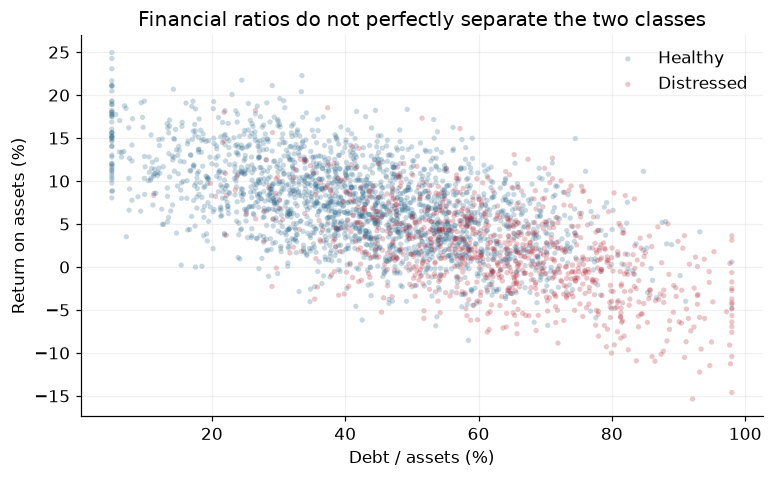

In [3]:
X, y = simulate_companies()
display(X.head().assign(Distressed=y[:5]).round(3))
print(f"Companies: {len(y):,} | Distressed: {y.mean():.1%}")

# Look at two ratios only. The models will use all six.
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, color, name in [(0, BLUE, "Healthy"), (1, RED, "Distressed")]:
    mask = y == label
    ax.scatter(100*X.loc[mask, "Debt / assets"], 100*X.loc[mask, "Return on assets"],
               s=12, alpha=.25, color=color, label=name, edgecolors="none")
ax.set(title="Financial ratios do not perfectly separate the two classes",
       xlabel="Debt / assets (%)", ylabel="Return on assets (%)")
ax.legend(frameon=False)
plt.show()

## 2. Train three different classifiers

A classifier learns a relationship between financial ratios and a company's future condition. It produces a score $p_j(x)\in[0,1]$, intended to estimate

$$p_j(x)\approx P(Y=1\mid X=x).$$

We use three different models (the original article uses logistic regression, a neural network and support vector regression):

| Model | How it learns |
|---|---|
| Logistic regression | Learns a weighted sum of the financial ratios, then applies a sigmoid to obtain a score between 0 and 1. |
| Random forest | Combines many decision trees that split companies using rules such as "debt / assets > 65%". |
| Neural network | Learns nonlinear combinations of the ratios through a small hidden layer. |

A model's `predict_proba` output is an **estimated probability**, not a guarantee of good probabilistic calibration. Different models can be biased or overconfident.

### Training, validation and testing

We separate companies into three disjoint groups before fitting anything: **60% training**, **20% validation** (to estimate model reliability later), and **20% test** (to evaluate the final methods). Standardisation is fitted on training data only through a scikit-learn pipeline. The split is random and stratified because these simulated companies are independent draws; with real dated financial data, use a forward-in-time evaluation and avoid company overlap across splits.

In [4]:
def build_models():
    """Define three classifiers. Pipelines scale features when necessary."""
    return {
        "Logistic regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
        "Random forest": RandomForestClassifier(
            n_estimators=150, max_depth=6, min_samples_leaf=12, random_state=42, n_jobs=1),
        "Neural network": make_pipeline(
            StandardScaler(), MLPClassifier(hidden_layer_sizes=(12,), max_iter=500,
                                             alpha=.02, early_stopping=True,
                                             random_state=42)),
    }


def fit_models(models, X_train, y_train):
    """Each classifier learns from the same training companies."""
    for name, model in models.items():
        model.fit(X_train, y_train)
    return models


def predict_probabilities(models, X_new):
    """One row per company, one column per model: P(distress)."""
    return pd.DataFrame({name: model.predict_proba(X_new)[:, 1]
                         for name, model in models.items()}, index=X_new.index)

Training: 1800 | Validation: 600 | Test: 600


,Logistic regression,Random forest,Neural network
Company ID,,,
2806,0.913,0.916,0.822
1536,0.639,0.590,0.609
534,0.039,0.190,0.280
2457,0.048,0.080,0.390
2312,0.534,0.441,0.672


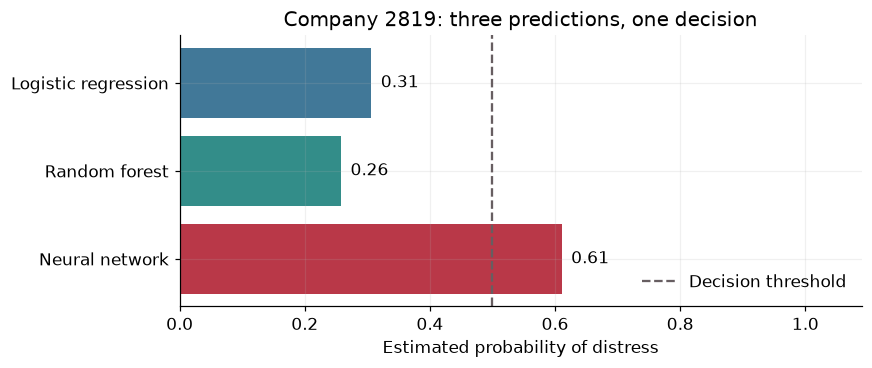

In [5]:
# Split row indices so that X and y always stay aligned.
train, remaining = train_test_split(np.arange(len(y)), test_size=.40,
                                    stratify=y, random_state=42)
val, test = train_test_split(remaining, test_size=.50,
                             stratify=y[remaining], random_state=42)
assert not (set(train) & set(val) or set(train) & set(test) or set(val) & set(test))

models = fit_models(build_models(), X.iloc[train], y[train])
p_val = predict_probabilities(models, X.iloc[val])
p_test = predict_probabilities(models, X.iloc[test])
y_val, y_test = y[val], y[test]
names = list(models)
print(f"Training: {len(train)} | Validation: {len(val)} | Test: {len(test)}")
display(p_test.head().round(3).rename_axis("Company ID"))

# Choose a test company where the models vote differently. Among those,
# choose the largest spread. We never use its true label for this choice.
spread = p_test.max(axis=1) - p_test.min(axis=1)
different_votes = (p_test.min(axis=1) < .5) & (p_test.max(axis=1) >= .5)
example_id = spread[different_votes].idxmax() if different_votes.any() else spread.idxmax()
example_p = p_test.loc[example_id]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(names, example_p, color=[BLUE, TEAL, RED], alpha=.88)
ax.axvline(.5, color=GREY, linestyle="--", label="Decision threshold")
for i, p in enumerate(example_p):
    ax.text(p+.015, i, f"{p:.2f}", va="center")
ax.set(xlim=(0, 1.09), xlabel="Estimated probability of distress",
       title=f"Company {example_id}: three predictions, one decision")
ax.invert_yaxis(); ax.legend(frameon=False, loc="lower right")
plt.show()

## 3. What is normally done? Ensemble learning

Instead of trusting a single model, an *ensemble* combines predictions. This is common in machine learning because models can make different errors. There is no universal guarantee that an ensemble is better.

Two simple methods are:

**Majority voting.** Each model votes for distress if $p_j(x)\geq 0.5$. With three models, two votes suffice.

$$\widehat y_{\mathrm{vote}}(x)=\mathbf{1}\left\{\frac{1}{J}\sum_{j=1}^{J}\mathbf{1}\{p_j(x)\geq 0.5\}\geq 0.5\right\}.$$

**Soft voting / probability averaging.** Keep the continuous scores and average them:

$$\overline p(x)=\frac1J\sum_{j=1}^{J}p_j(x),\qquad \widehat y(x)=\mathbf{1}\{\overline p(x)\geq 0.5\}.$$

The two methods discard different information. Hard voting throws away the strength of each prediction. Soft voting retains it but compresses all the scores into a single number.

**Question.** Two models give scores $(0.5,0.5)$ for company A and $(0.9,0.1)$ for company B. Both average to 0.5. Are the two situations really the same? The second contains substantial disagreement, while in the first neither source strongly favours a class. We would like to retain some of this information, along with how much we trust each model.

In [6]:
def conventional_ensembles(probabilities, threshold=.5):
    """Return mean probability, fraction of positive votes, and labels."""
    mean_score = probabilities.mean(axis=1)
    vote_fraction = (probabilities >= threshold).mean(axis=1)
    return mean_score, vote_fraction, (mean_score >= threshold).astype(int), (vote_fraction >= .5).astype(int)


def classification_metrics(y_true, y_pred):
    """Accuracy, average class recall, and ability to detect distress."""
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Distress recall": recall_score(y_true, y_pred, zero_division=0)}

Company 2819: mean score = 0.392; votes for distress = 1/3


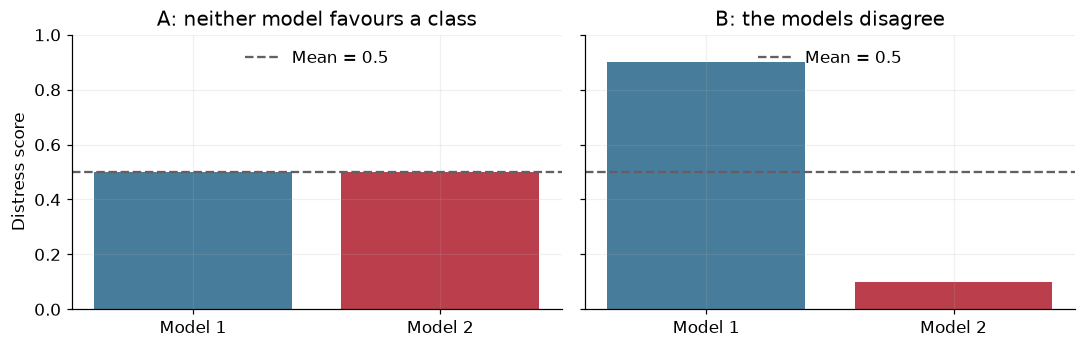

In [7]:
mean_score, vote_fraction, mean_label, vote_label = conventional_ensembles(p_test)
print(f"Company {example_id}: mean score = {mean_score.loc[example_id]:.3f}; "
      f"votes for distress = {int((example_p >= .5).sum())}/{len(names)}")

# We keep the test metrics until the final comparison. No tuning on test data.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, vals, title in zip(axes, [[.5,.5], [.9,.1]], ["A: neither model favours a class", "B: the models disagree"]):
    ax.bar(["Model 1", "Model 2"], vals, color=[BLUE, RED], alpha=.85)
    ax.axhline(np.mean(vals), color=GREY, linestyle="--", label="Mean = 0.5")
    ax.set(ylim=(0,1), title=title); ax.legend(frameon=False, loc="upper center")
axes[0].set_ylabel("Distress score")
fig.tight_layout(); plt.show()

## 4. Evidence theory: a richer way to represent a prediction

Xiao et al. combine models using **Dempster–Shafer evidence theory**. We now introduce the mathematical objects we need, one at a time.

### 4.1. Frame of discernment and mass functions

For a *single company*, the frame of discernment is the set of mutually exclusive and exhaustive hypotheses

$$\Theta=\{H,D\},$$

where $H$ means healthy and $D$ means distressed. Its power set consists of $\varnothing$, $\{H\}$, $\{D\}$ and $\Theta$.

A basic probability assignment (BPA), or **mass function**, is a map

$$m:2^\Theta\rightarrow[0,1],\qquad m(\varnothing)=0,\qquad \sum_{A\subseteq\Theta}m(A)=1.$$

A positive mass on $\{D\}$ represents evidence committed specifically to distress; a mass on $\{H\}$ supports health. Unlike an ordinary probability distribution, we may also assign mass to $\Theta$ without choosing between the two classes. This is **uncommitted support** (imprecision), not a third financial state.

### 4.2. From model predictions to evidence: reliability discounting

Suppose model $j$ predicts distress with score $p_j(x)$, but we assign the model a reliability $r_j\in[0,1]$. We discount the initial Bayesian mass (with all mass on singletons):

$$m_j(\{H\})=r_j(1-p_j(x)),\qquad m_j(\{D\})=r_j p_j(x),\qquad m_j(\Theta)=1-r_j.$$

If $r_j=1$, the original probability distribution is recovered. If $r_j=0$, we obtain vacuous evidence: no specific class is supported. This is Shafer-style reliability discounting, not the paper's original transformation. The choice of reliability remains a modelling assumption.

In [8]:
def discount_probability(p, reliability):
    """Convert a distress score (or array of scores) to [m(H), m(D), m(Theta)]."""
    p = np.asarray(p, dtype=float)
    r = np.asarray(reliability, dtype=float)
    if (not np.all(np.isfinite(p)) or not np.all(np.isfinite(r))
        or np.any((p < 0) | (p > 1)) or np.any((r < 0) | (r > 1))):
        raise ValueError("Scores and reliabilities must be finite and in [0, 1].")
    h = r * (1-p)
    d = r * p
    u = np.broadcast_to(1-r, h.shape)
    return np.stack([h, d, u], axis=-1)


def plot_masses(ax, masses, labels, title):
    """Stack three masses horizontally; each bar must sum to one."""
    masses = np.atleast_2d(masses)
    left = np.zeros(len(masses))
    for j, (name, color) in enumerate(zip(MASS_NAMES, MASS_COLORS)):
        ax.barh(labels, masses[:, j], left=left, color=color, label=name, alpha=.9)
        for i, v in enumerate(masses[:, j]):
            if v >= .09:
                ax.text(left[i]+v/2, i, f"{v:.2f}", color="white", ha="center", va="center", fontsize=10)
        left += masses[:, j]
    ax.set(xlim=(0,1), xlabel="Mass (total = 1)", title=title)
    ax.invert_yaxis()

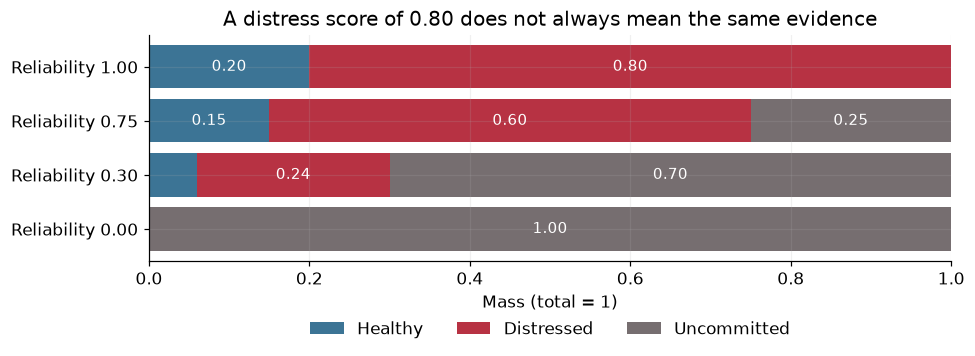

In [9]:
# Same model score p = 0.80, different levels of trust.
r_demo = np.array([1.0, .75, .30, 0.0])
m_demo = discount_probability(.80, r_demo)
assert np.allclose(m_demo.sum(axis=1), 1)
fig, ax = plt.subplots(figsize=(9, 3.5))
plot_masses(ax, m_demo, [f"Reliability {r:.2f}" for r in r_demo],
            "A distress score of 0.80 does not always mean the same evidence")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5,-.20))
fig.tight_layout(); plt.show()

### 4.3. Belief and plausibility

The belief function measures the evidence that is fully committed to an event $A$; plausibility also includes the evidence that is compatible with it:

$$\operatorname{Bel}(A)=\sum_{B\subseteq A}m(B),\qquad
\operatorname{Pl}(A)=\sum_{B\cap A\neq\varnothing}m(B)=1-\operatorname{Bel}(A^c).$$

In our binary problem,

$$\operatorname{Bel}(\{D\})=m(\{D\}),\qquad \operatorname{Pl}(\{D\})=m(\{D\})+m(\Theta).$$

We can interpret $[\operatorname{Bel}(\{D\}),\operatorname{Pl}(\{D\})]$ as the range of probabilities of distress compatible with this belief function. Its width equals $m(\Theta)$. It is **not** a frequentist confidence interval or a conformal prediction interval; we have not established a statistical coverage guarantee.

For example, $p=0.8$, $r=0.75$ gives $m(H)=0.15$, $m(D)=0.60$ and $m(\Theta)=0.25$, so the distress bounds are $[0.60,0.85]$. With no trust in the source, the bounds become $[0,1]$.

This represents imprecision about the prediction, rather than only the randomness of the future financial outcome. The reliability estimate is still a heuristic, not an objectively identified amount of epistemic uncertainty.

In [10]:
def distress_bounds(mass):
    """Lower and upper probabilities of distress for a binary mass."""
    return mass[..., 1], mass[..., 1] + mass[..., 2]


def plot_bounds(ax, lower, upper, labels, points=None, title="Belief–plausibility intervals"):
    """Draw one interval per case, and optionally a point score."""
    yy = np.arange(len(labels))
    ax.hlines(yy, lower, upper, color=RED, linewidth=5, alpha=.75,
              label="Bel–Pl interval")
    ax.scatter(lower, yy, color=RED, s=25, zorder=3)
    ax.scatter(upper, yy, color=RED, s=25, zorder=3)
    if points is not None:
        ax.scatter(points, yy, marker="D", color=TEAL, s=33, zorder=4, label="Mean model score")
    ax.axvline(.5, color=GREY, linestyle="--", label="Threshold 0.5")
    ax.set(yticks=yy, yticklabels=labels, xlim=(-.02,1.02), xlabel="Distress probability / score", title=title)
    ax.invert_yaxis()

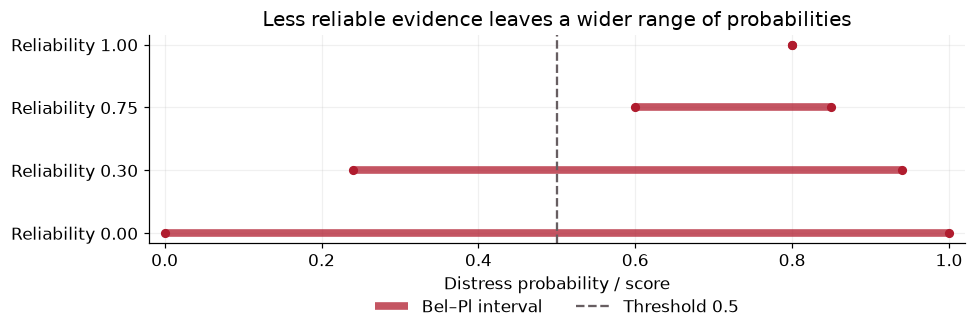

In [11]:
bel_demo, pl_demo = distress_bounds(m_demo)
fig, ax = plt.subplots(figsize=(9, 3.3))
plot_bounds(ax, bel_demo, pl_demo, [f"Reliability {r:.2f}" for r in r_demo],
            title="Less reliable evidence leaves a wider range of probabilities")
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(.5,-.20))
fig.tight_layout(); plt.show()

## 5. The key operation: Dempster's rule of combination

We now have two sources of evidence, with masses $m_1$ and $m_2$ on the same frame. How can we combine them?

Dempster's rule first multiplies the masses of pairs of focal sets and assigns each product to their intersection. For example, $\{D\}\cap\Theta=\{D\}$, but $\{D\}\cap\{H\}=\varnothing$.

The **conflict** is the total product assigned to the empty set:

$$K=\sum_{B\cap C=\varnothing}m_1(B)m_2(C).$$

For every nonempty $A\subseteq\Theta$, the normalized combination is

$$ (m_1\oplus m_2)(A)=\frac{\sum_{B\cap C=A}m_1(B)m_2(C)}{1-K},\qquad (m_1\oplus m_2)(\varnothing)=0.$$

The normalization redistributes the non-conflicting products proportionally; it does **not** leave the conflict as a third class or automatically turn conflict into ignorance. The rule is undefined for $K=1$.

### 5.1. A worked example

Suppose the first model gives masses $(h_1,d_1,u_1)$ and the second gives $(h_2,d_2,u_2)$, ordered as $H,D,\Theta$. The intersection table contains every product:

| $\cap$ | $\{H\}$ | $\{D\}$ | $\Theta$ |
|---|---|---|---|
| $\{H\}$ | $H$ | $\varnothing$ | $H$ |
| $\{D\}$ | $\varnothing$ | $D$ | $D$ |
| $\Theta$ | $H$ | $D$ | $\Theta$ |

Thus the binary form of Dempster's rule is particularly simple:

$$\begin{aligned}
K &= h_1d_2+d_1h_2,\\
m(H)&=\frac{h_1h_2+h_1u_2+u_1h_2}{1-K},\\
m(D)&=\frac{d_1d_2+d_1u_2+u_1d_2}{1-K},\\
m(\Theta)&=\frac{u_1u_2}{1-K}.
\end{aligned}$$

For model 1, let $p_1=0.80$ and $r_1=0.75$; for model 2, let $p_2=0.60$ and $r_2=0.85$. We will compute their evidence, the conflict and the combined belief–plausibility interval.

In [12]:
def dempster_combine(m1, m2):
    """Combine binary masses; return combined mass and pre-normalization conflict.

    Accepts either a single triple or an array of triples, one per company.
    """
    m1, m2 = np.asarray(m1, float), np.asarray(m2, float)
    for m in (m1, m2):
        if m.shape[-1] != 3 or not np.all(np.isfinite(m)) or np.any(m < 0) or not np.allclose(m.sum(axis=-1), 1):
            raise ValueError("Each mass must contain three nonnegative values summing to 1.")
    h1, d1, u1 = np.moveaxis(m1, -1, 0)
    h2, d2, u2 = np.moveaxis(m2, -1, 0)
    K = h1*d2 + d1*h2                       # disjoint intersections
    normalizer = 1-K
    if np.any(normalizer <= 1e-12):
        raise ValueError("Total or numerically near-total conflict: Dempster's rule is undefined or unstable.")
    h = (h1*h2 + h1*u2 + u1*h2) / normalizer
    d = (d1*d2 + d1*u2 + u1*d2) / normalizer
    u = u1*u2 / normalizer
    return np.stack([h, d, u], axis=-1), K


def fuse_sources(masses):
    """Combine J sources in order; return mass and total conjunctive conflict.

    Input shape: (number of sources, ..., 3). The total pre-normalization
    conflict is 1 minus the product of the sequential non-conflict factors.
    """
    if len(masses) == 0:
        raise ValueError("At least one source is needed.")
    combined = np.asarray(masses[0], float)
    survival = np.ones(combined.shape[:-1])
    for source in masses[1:]:
        combined, K = dempster_combine(combined, source)
        survival *= 1-K
    return combined, 1-survival

,H,D,Theta
H,0.051,0.0765,0.0225
D,0.204,0.3060,0.0900
Theta,0.085,0.1275,0.0375


Conflict K = 0.2805; normalization factor 1-K = 0.7195
Combined masses: H=0.2203, D=0.7276, Theta=0.0521
Combined distress interval: [0.7276, 0.7797]


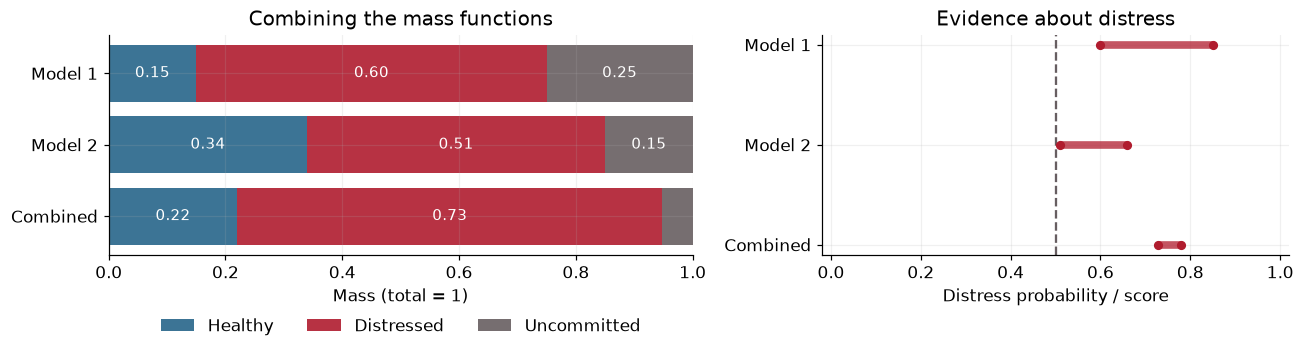

In [13]:
m1 = discount_probability(.80, .75)
m2 = discount_probability(.60, .85)
fused, conflict = dempster_combine(m1, m2)

# The actual nine products, BEFORE normalization.
products = pd.DataFrame(np.outer(m1, m2), index=["H", "D", "Theta"],
                        columns=["H", "D", "Theta"])
display(products.round(4))
print(f"Conflict K = {conflict:.4f}; normalization factor 1-K = {1-conflict:.4f}")
print(f"Combined masses: H={fused[0]:.4f}, D={fused[1]:.4f}, Theta={fused[2]:.4f}")
bel, pl = distress_bounds(fused)
print(f"Combined distress interval: [{bel:.4f}, {pl:.4f}]")

# Sanity checks: normalization, vacuous evidence as identity, commutativity.
assert np.isclose(fused.sum(), 1)
assert np.allclose(dempster_combine(m1, [0,0,1])[0], m1)
assert np.allclose(dempster_combine(m2, m1)[0], fused)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios":[1.25,1]})
stack = np.vstack([m1,m2,fused]); labs = ["Model 1", "Model 2", "Combined"]
plot_masses(axes[0], stack, labs, "Combining the mass functions")
lo, hi = distress_bounds(stack)
plot_bounds(axes[1], lo, hi, labs, title="Evidence about distress")
axes[0].legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5,-.22))
fig.tight_layout(); plt.show()

### 5.2. Agreement, conflict and ignorance are not the same

Let us return to the two companies with the same mean score of 0.5. If both sources have reliability 0.8, their uncommitted masses are identical, but their conflicts differ. In fact, even two sources with diffuse probabilistic scores can yield positive $K$: conflict is the mass of disjoint intersections in the conjunctive product, not simply the difference between two point estimates.

We also add a third scenario in which both models support distress. Notice how the combination can strengthen agreement and reduce uncommitted mass. **This is only justified if the sources can reasonably be treated as distinct evidence.** Classifiers trained on the same data can be strongly dependent. Combining duplicates may create unjustified precision; discounting alone does not guarantee that this problem is solved.

,Mean score,Conflict K,Bel(D),Pl(D),Uncommitted
Weak opinions,0.50,0.320,0.471,0.529,0.059
Opposing opinions,0.50,0.525,0.458,0.542,0.084
Agree on distress,0.85,0.163,0.878,0.925,0.048


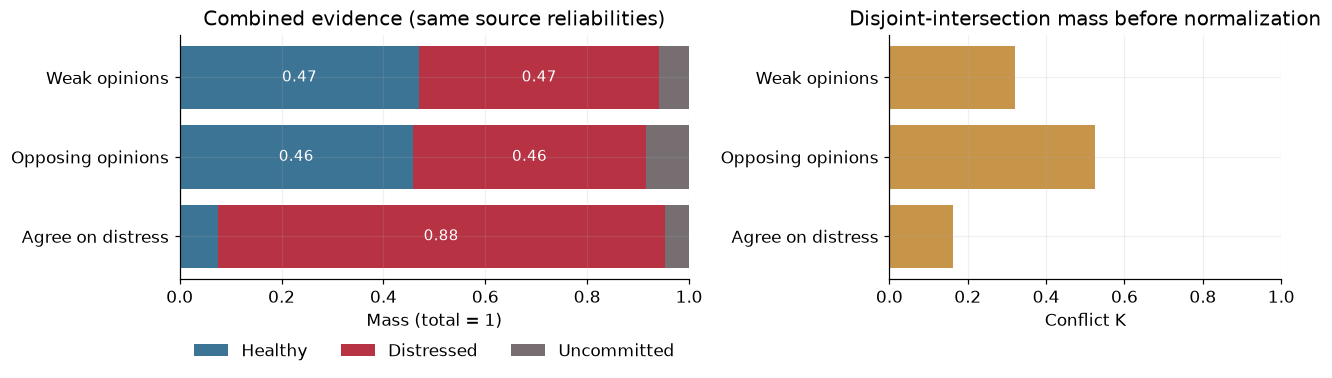

In [14]:
cases = [("Weak opinions", .5, .5), ("Opposing opinions", .9, .1), ("Agree on distress", .85, .85)]
case_masses, case_conflicts, case_means = [], [], []
for label, p1, p2 in cases:
    m, k = dempster_combine(discount_probability(p1, .8), discount_probability(p2, .8))
    case_masses.append(m); case_conflicts.append(k); case_means.append((p1+p2)/2)
case_masses = np.array(case_masses)
lo, hi = distress_bounds(case_masses)
case_table = pd.DataFrame({"Mean score": case_means, "Conflict K": case_conflicts,
                           "Bel(D)": lo, "Pl(D)": hi, "Uncommitted": case_masses[:,2]},
                          index=[c[0] for c in cases])
display(case_table.round(3))
fig, axes = plt.subplots(1,2,figsize=(12,3.7),gridspec_kw={"width_ratios":[1.3,1]})
plot_masses(axes[0], case_masses, case_table.index, "Combined evidence (same source reliabilities)")
axes[1].barh(case_table.index, case_conflicts, color=GOLD, alpha=.9)
axes[1].set(xlim=(0,1), xlabel="Conflict K", title="Disjoint-intersection mass before normalization")
axes[1].invert_yaxis()
axes[0].legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5,-.20))
fig.tight_layout(); plt.show()

## 6. Apply evidence theory to our financial classifiers

### 6.1. How much do we trust each classifier?

In the original paper, rough set theory measures the extra information provided by each classifier through conditional entropy. Here we use a simpler reliability heuristic computed **only on the validation set**, not on training or test labels.

Ordinary accuracy can be misleading if most companies are healthy. We use balanced accuracy, the average of the correct classification rate for distressed and healthy companies:

$$b_j=\tfrac12(\mathrm{TPR}_j+\mathrm{TNR}_j),\qquad r_j=\max(0,2b_j-1).$$

A classifier with balanced accuracy 0.5 receives reliability zero, and a perfect one receives reliability one. This choice is deliberately simple and conservative. It does not estimate a mathematically guaranteed reliability probability, and it does not measure conditional informativeness as rough sets do. Unlike normalized ensemble weights, the $r_j$ values need not sum to one.

For all unseen companies, we transform each model's score into a mass, then combine the three sources using Dempster's rule. The models have been trained on the same companies, so the rule is used as an illustrative fusion strategy, **not** as proof that the evidence is independent or that the resulting bounds are calibrated.

In [15]:
def estimate_reliabilities(probabilities, y_true):
    """Balanced-accuracy skill above chance, on held-out validation data."""
    balanced = pd.Series({name: balanced_accuracy_score(y_true, probabilities[name] >= .5)
                          for name in probabilities.columns})
    reliability = (2*balanced - 1).clip(0, 1)
    return pd.DataFrame({"Validation balanced accuracy": balanced, "Reliability": reliability})


def evidence_from_models(probabilities, reliabilities):
    """Construct the mass of every model for every company, then fuse them."""
    source_masses = np.stack([discount_probability(probabilities[name].to_numpy(),
                                                    reliabilities.loc[name])
                              for name in probabilities.columns])
    combined, conflict = fuse_sources(source_masses)
    return source_masses, combined, conflict

,Validation balanced accuracy,Reliability
Logistic regression,0.711,0.422
Random forest,0.703,0.406
Neural network,0.707,0.414


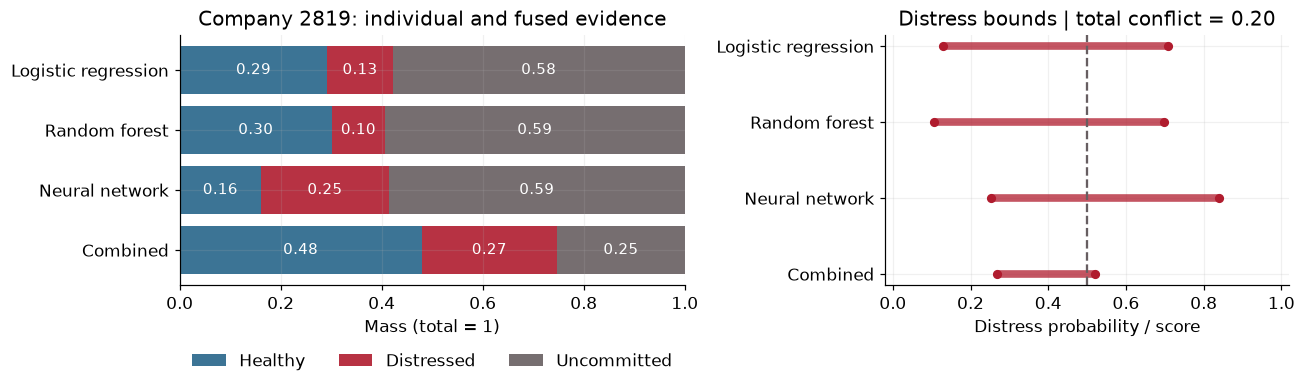

In [16]:
reliability_table = estimate_reliabilities(p_val, y_val)
reliabilities = reliability_table["Reliability"]
display(reliability_table.round(3))
source_masses, combined, K_all = evidence_from_models(p_test, reliabilities)
bel, pl = distress_bounds(combined)
assert np.allclose(combined.sum(axis=1), 1)
assert np.all((bel >= 0) & (pl <= 1+1e-10) & (bel <= pl))

# Revisit the company selected in section 2 (by model disagreement).
i = p_test.index.get_loc(example_id)
stack = np.vstack([source_masses[:, i, :], combined[i]])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios":[1.25,1]})
labels = names + ["Combined"]
plot_masses(axes[0], stack, labels, f"Company {example_id}: individual and fused evidence")
lo, hi = distress_bounds(stack)
plot_bounds(axes[1], lo, hi, labels, title=f"Distress bounds | total conflict = {K_all[i]:.2f}")
axes[0].legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5,-.21))
fig.tight_layout(); plt.show()

### 6.2. From evidence to a financial decision

Sometimes we need a single score. One common transformation is the *pignistic probability*, which distributes the uncommitted mass equally over the two hypotheses:

$$\operatorname{BetP}(D)=m(\{D\})+\tfrac12m(\Theta).$$

This is the midpoint of the belief–plausibility interval. It is a decision-oriented transformation, not a guarantee of statistical calibration. We can compare its forced binary prediction to the other classifiers using the same threshold $\tau=0.5$.

The more interesting alternative is to retain the interval and make a decision only when it is robust to all probabilities compatible with the combined mass:

$$\widehat y_{\mathrm{robust}}(x)=\begin{cases}
1\ (\text{high risk}),&\operatorname{Bel}(D)\geq\tau,\\
0\ (\text{low risk}),&\operatorname{Pl}(D)<\tau,\\
\text{review},&\operatorname{Bel}(D)<\tau\leq\operatorname{Pl}(D).
\end{cases}$$

Review is **not** a new possible financial state. It is an action: we postpone the binary decision until more evidence is available. Robust here means robust within the adopted belief function; the quality of that representation still needs validation. The threshold is illustrative rather than an optimal lending rule.

In [17]:
def pignistic_probability(mass):
    """BetP(D): divide the uncommitted mass equally over H and D."""
    return mass[..., 1] + .5*mass[..., 2]


def robust_decision(mass, threshold=.5):
    """1 = high risk, 0 = low risk, -1 = review (abstain)."""
    lower, upper = distress_bounds(mass)
    return np.where(lower >= threshold, 1, np.where(upper < threshold, 0, -1))

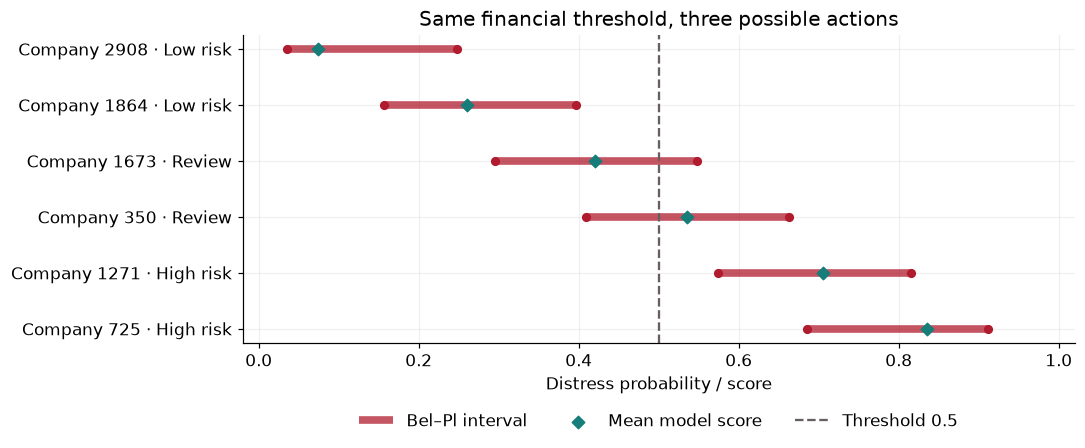

,Mean,BetP,Bel(D),Pl(D),Conflict,Decision,Actual distress
Company ID,,,,,,,
2908,0.074,0.141,0.035,0.248,0.056,Low risk,0
1864,0.261,0.276,0.156,0.396,0.163,Low risk,0
1673,0.421,0.422,0.296,0.548,0.204,Review,0
350,0.536,0.536,0.410,0.663,0.206,Review,0
1271,0.706,0.695,0.574,0.816,0.170,High risk,1
725,0.836,0.798,0.685,0.912,0.113,High risk,1


In [18]:
THRESHOLD = .5
betp = pignistic_probability(combined)
robust = robust_decision(combined, THRESHOLD)
label_names = {0: "Low risk", 1: "High risk", -1: "Review"}

# Select representative cases by score/decision, NOT by their true labels.
selected = []
for decision in [0,-1,1]:
    candidates = np.flatnonzero(robust == decision)
    if len(candidates):
        ordered = candidates[np.argsort(betp[candidates])]
        selected.extend(np.unique(ordered[[len(ordered)//4, len(ordered)*3//4]]).tolist())
selected = np.array(sorted(set(selected), key=lambda i: betp[i]), dtype=int)
labels = [f"Company {p_test.index[i]} · {label_names[robust[i]]}" for i in selected]
fig, ax = plt.subplots(figsize=(10,4.3))
plot_bounds(ax, bel[selected], pl[selected], labels, mean_score.to_numpy()[selected],
            title="Same financial threshold, three possible actions")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5,-.18))
fig.tight_layout(); plt.show()

# Each company's actual label is now revealed for interpretation.
case_results = pd.DataFrame({"Mean": mean_score.to_numpy()[selected], "BetP": betp[selected],
                             "Bel(D)": bel[selected], "Pl(D)": pl[selected], "Conflict": K_all[selected],
                             "Decision": [label_names[v] for v in robust[selected]],
                             "Actual distress": y_test[selected]}, index=p_test.index[selected])
display(case_results.round(3).rename_axis("Company ID"))

## 7. Compare the methods on unseen companies

We now use the held-out test labels to evaluate the individual classifiers, majority voting, probability averaging and the Dempster–Shafer ensemble. We use three metrics:

- **Accuracy:** fraction of all companies correctly classified.
- **Balanced accuracy:** average of recall in the healthy and distressed classes.
- **Distress recall:** fraction of actual distressed companies detected (false negatives matter in credit risk).

For the robust decision rule we also report the **automatic decision rate** (fraction not sent to review) and accuracy **among automatic decisions**. An increase in this selective accuracy is not a free improvement: some companies are left undecided. It must not be directly compared with accuracy on all companies without accounting for the review rate. This decision rate is different from conformal prediction coverage in the previous notebook.

Test metrics (all companies; percentages)


,Accuracy,Balanced accuracy,Distress recall
Logistic regression,81.0,75.0,60.5
Random forest,80.0,72.5,54.2
Neural network,76.8,76.5,75.7
Majority voting,80.3,74.7,61.0
Mean probability,80.5,75.2,62.1
D-S (BetP),80.5,75.2,62.1


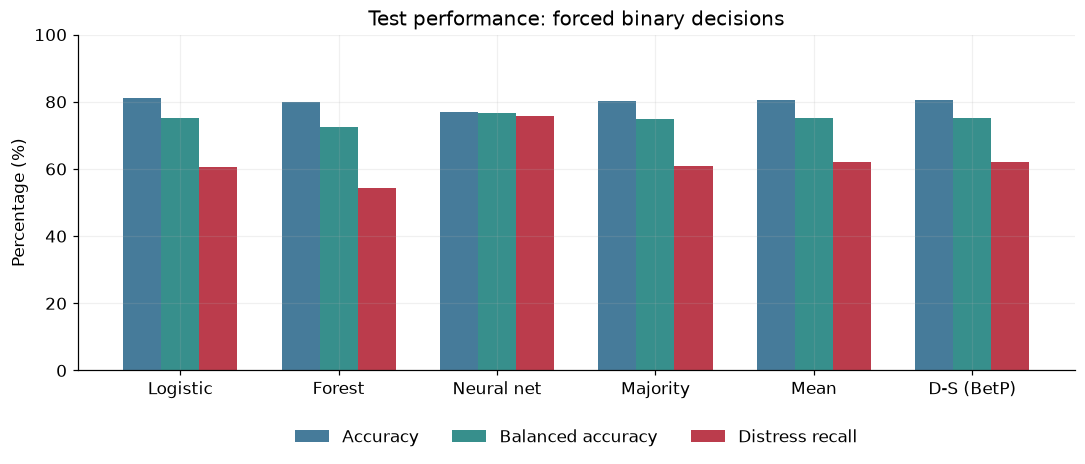

In [19]:
# Every forced-decision method is evaluated on exactly the same test set.
forced = {name: (p_test[name].to_numpy() >= THRESHOLD).astype(int) for name in names}
forced.update({"Majority voting": vote_label.to_numpy(),
               "Mean probability": mean_label.to_numpy(),
               "D-S (BetP)": (betp >= THRESHOLD).astype(int)})
metrics = pd.DataFrame({name: classification_metrics(y_test, pred)
                        for name, pred in forced.items()}).T
print("Test metrics (all companies; percentages)")
display((100*metrics).round(1))

fig, ax = plt.subplots(figsize=(10,4.4))
positions = np.arange(len(metrics)); width = .24
for j, (metric, color) in enumerate(zip(metrics.columns, [BLUE, TEAL, RED])):
    ax.bar(positions+(j-1)*width, 100*metrics[metric], width, color=color, alpha=.86, label=metric)
ax.set(xticks=positions, xticklabels=["Logistic", "Forest", "Neural net", "Majority", "Mean", "D-S (BetP)"],
       ylim=(0,100), ylabel="Percentage (%)", title="Test performance: forced binary decisions")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(.5,-.13))
fig.tight_layout(); plt.show()

Selective decision performance (rates as percentages; counts as integers)


,Automatic decision rate,Review rate,Accuracy on automatic cases,False negatives among automatic cases (count)
Mean (forced),100.0,0.0,80.5,67.0
Mean (matched review budget),78.0,22.0,87.2,42.0
D-S (robust),78.0,22.0,87.2,42.0


Automatic-case accuracy: D-S = 87.2%; mean at the same review budget = 87.2%.


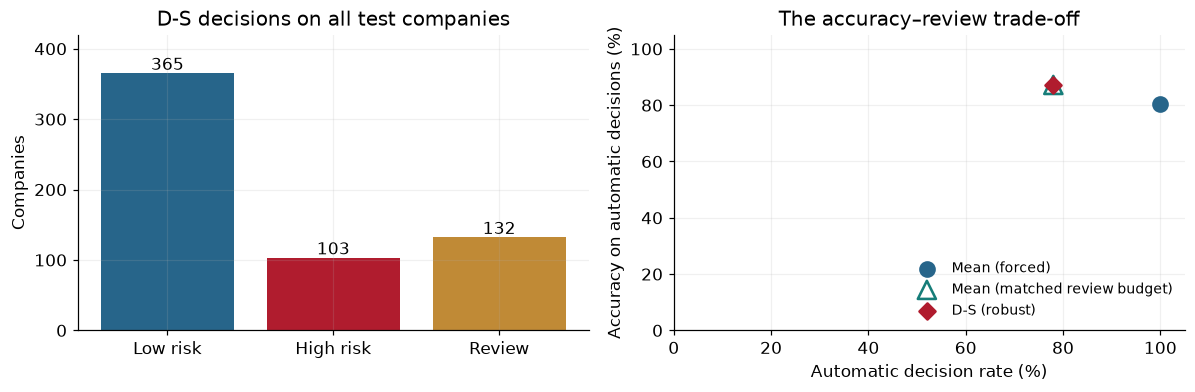

D-S has referred 132 of 600 companies for review.


In [20]:
def selective_metrics(y_true, decisions):
    """Quantify performance when a method can abstain (-1)."""
    auto = decisions != -1
    return {"Automatic decision rate": auto.mean(),
            "Review rate": (~auto).mean(),
            "Accuracy on automatic cases": (decisions[auto] == y_true[auto]).mean() if auto.any() else np.nan,
            "False negatives among automatic cases (count)": int(((decisions == 0) & (y_true == 1)).sum())}

# Fairer comparison: allow mean-probability voting to defer the SAME number
# of cases, starting with scores closest to the threshold. This is a descriptive
# matched-budget benchmark, not a threshold optimized using test labels.
n_review = int((robust == -1).sum())
mean_selective = mean_label.to_numpy().copy()
review_order = np.argsort(np.abs(mean_score.to_numpy() - THRESHOLD), kind="stable")
mean_selective[review_order[:n_review]] = -1
selective = pd.DataFrame({"Mean (forced)": selective_metrics(y_test, mean_label.to_numpy()),
                          "Mean (matched review budget)": selective_metrics(y_test, mean_selective),
                          "D-S (robust)": selective_metrics(y_test, robust)}).T
print("Selective decision performance (rates as percentages; counts as integers)")
show = selective.copy(); show.iloc[:, :3] *= 100
with pd.option_context("display.max_columns", None):
    display(show.round(1))
print(f"Automatic-case accuracy: D-S = {selective.loc['D-S (robust)', 'Accuracy on automatic cases']:.1%}; "
      f"mean at the same review budget = {selective.loc['Mean (matched review budget)', 'Accuracy on automatic cases']:.1%}.")

fig, axes = plt.subplots(1,2,figsize=(11,3.7))
counts = np.array([(robust==0).sum(), (robust==1).sum(), (robust==-1).sum()])
axes[0].bar(["Low risk", "High risk", "Review"], counts, color=[BLUE, RED, GOLD])
for i,n in enumerate(counts): axes[0].text(i,n+5,str(n),ha="center")
axes[0].set(ylabel="Companies", title="D-S decisions on all test companies", ylim=(0,max(counts)*1.15))
for i, row in enumerate(selective.itertuples(index=False, name=None)):
    axes[1].scatter(100*row[0],100*row[2],s=[85,140,55][i], marker=["o","^","D"][i],
                    color=[BLUE,TEAL,RED][i],label=selective.index[i],zorder=3+i,
                    facecolors="none" if i==1 else [BLUE,TEAL,RED][i], linewidths=1.7)
axes[1].set(xlim=(0,105),ylim=(0,105),xlabel="Automatic decision rate (%)",
            ylabel="Accuracy on automatic decisions (%)",title="The accuracy–review trade-off")
axes[1].legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout(); plt.show()

print(f"D-S has referred {n_review} of {len(y_test)} companies for review.")

### How should we interpret the results?

Look at the tables above. Does the D-S point prediction outperform every individual classifier? Not necessarily. We have not tuned the simulation to guarantee a victory for Dempster's rule. The standard averaging and voting methods remain useful baselines, and the additional matched-review comparison shows that conventional models can also abstain.

What does evidence theory add? A structured description of **support, imprecision and conflict** and an explicit mechanism for discounting sources. In particular, we can use the lower and upper probabilities to explain why a given case needs review. These quantities are properties of the evidence model, not empirically validated probabilities of the true risk unless additional assumptions and calibration checks are justified.

## 8. How can we use this information in finance?

**Example 1 — Credit screening.** Imagine a bank has a review threshold of 20% risk of distress over a specified horizon (illustrative, not a regulatory standard). A company's assessed risk interval is $[0.08,0.27]$. The interval straddles the threshold: the bank cannot confidently assign it to either risk category under the adopted evidence model. It could request more recent cash-flow statements, debt schedules or independent analyst assessments before making a lending decision. By contrast, an interval $[0.03,0.11]$ lies entirely below the threshold, while $[0.25,0.43]$ lies above it. Neither category automatically means grant or deny a loan; other rules and costs matter.

**Example 2 — Expected credit loss sensitivity.** Suppose a hypothetical exposure is £100,000 and loss given default is 40%. If a separate, appropriately validated belief function bounds the **probability of default** (not simply distress) between 5% and 12% for the same horizon, then under fixed exposure and loss severity:

$$\mathrm{EL}=\mathrm{EAD}\times\mathrm{PD}\times\mathrm{LGD},$$

$$\mathrm{EL}\in[100{,}000\cdot0.05\cdot0.40,\;100{,}000\cdot0.12\cdot0.40]=[£2{,}000,£4{,}800].$$

The upper end illustrates how uncertainty about default risk can affect a conservative loss assessment. This is a simplified calculation, not a complete regulatory provisioning model or a recommendation to use these numbers for lending.

## 9. Optional experiment — what if we trust the sources more?

Repeat the fusion without refitting any classifiers. Increase or decrease a reliability multiplier and observe the average interval width, conflict and review rate. The original experiment corresponds to `RELIABILITY_MULTIPLIER = 1.0`. Do not choose the multiplier by maximising test accuracy: in a real project it must be specified or tuned on separate validation data.

Mean interval width: 0.234
Mean total conflict: 0.135
Review rate: 22.0%

Single source interval: [0.48 0.88]
Same source counted twice: [0.694 0.875]
The latter may look more precise, although no new information was obtained.


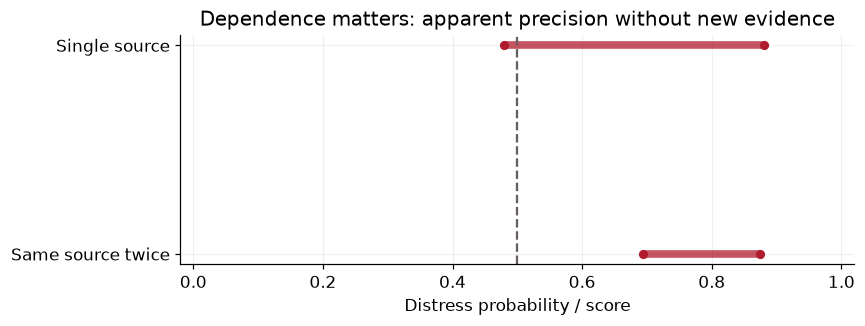

In [21]:
# Try changing this to 0.5, 1.5 or 2.0, then rerun this cell.
RELIABILITY_MULTIPLIER = 1.0
modified = (reliabilities*RELIABILITY_MULTIPLIER).clip(0,1)
_, m_alt, k_alt = evidence_from_models(p_test, modified)
lo_alt, hi_alt = distress_bounds(m_alt)
alt_decisions = robust_decision(m_alt, THRESHOLD)
print(f"Mean interval width: {np.mean(hi_alt-lo_alt):.3f}")
print(f"Mean total conflict: {np.mean(k_alt):.3f}")
print(f"Review rate: {np.mean(alt_decisions == -1):.1%}")

# A separate warning: copying the SAME model is not new evidence.
original = discount_probability(.8,.6)
duplicated, _ = dempster_combine(original, original)
print("\nSingle source interval:", np.round(distress_bounds(original),3))
print("Same source counted twice:", np.round(distress_bounds(duplicated),3))
print("The latter may look more precise, although no new information was obtained.")

fig, ax = plt.subplots(figsize=(8,3.1))
plot_bounds(ax, np.array([distress_bounds(original)[0],distress_bounds(duplicated)[0]]),
            np.array([distress_bounds(original)[1],distress_bounds(duplicated)[1]]),
            ["Single source", "Same source twice"], title="Dependence matters: apparent precision without new evidence")
fig.tight_layout(); plt.show()

**Takeaway.** An ensemble need not reduce all information to one number. Dempster–Shafer theory provides a way to represent partial support, discount less reliable sources and combine evidence, while also retaining conflict and imprecision for interpretation. It is not a guaranteed improvement in accuracy or calibration; the quality and dependence of the sources matter.